<a href="https://colab.research.google.com/github/bsheese/387/blob/main/22_images/22_1_Transfer_Learning/22_1_2_What_CNNs_Get_Wrong.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Images: Part 4
## What Image Models Get Wrong

---

## What This Notebook Is About

A test accuracy like 0.90 describes how a model does on test images that resemble its training images. It says nothing about why the model gets its answers right, or about what happens on images that are different. This notebook looks at four ways image models fail, each of which has caused real problems:

1. **Shortcut learning**: the model finds an easy clue in the training data that has nothing to do with the task, and relies on it
2. **Distribution shift**: the images the model meets in use differ from its training images in ways that matter
3. **Adversarial examples**: tiny, deliberate changes to pixels that a person can't see completely change the answer
4. **Bias against groups of people**: a model that's accurate on average can be much less accurate for some groups

The first three are demonstrated on models from this unit. The fourth is about face-analysis systems and is discussed from published research, without any face data.

The notebook trains one small network and runs the 19_0 Pets model on a few hundred altered photos. It's saved with its outputs; on a CPU it takes a minute or two to run.

In [1]:
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torchvision import datasets, models, transforms as T
from PIL import Image, ImageEnhance, ImageFilter

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

DATA_URL = 'https://raw.githubusercontent.com/bsheese/387/main/data/'

def fetch(name):
    # Download a file from the course's data folder, unless it is already here.
    if not os.path.exists(name):
        urllib.request.urlretrieve(DATA_URL + name, name)
    return name

loss_fn = nn.CrossEntropyLoss()

device: cpu


---

## Section 1: Shortcut Learning

A network learns whatever pattern in its training data best predicts the labels. Usually that's the thing we care about. But if something else in the images happens to predict the label, such as a watermark, a background or a marker, the network can learn that instead, and nothing in an ordinary train/validation/test split will reveal it.

To see this happen, take the Fashion-MNIST images from unit 21 and plant a shortcut: a small white square in the top row of each image, in a position that depends on the class. Class 0 gets the square near the left, class 9 near the right.

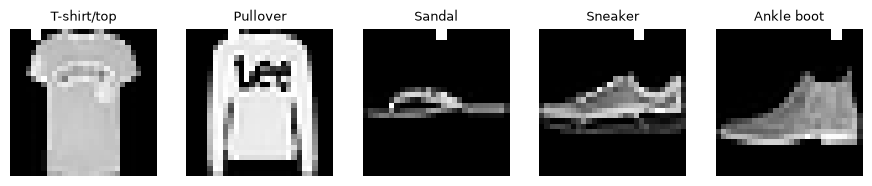

In [2]:
data = np.load(fetch('fashion10k.npz'))
CLASSES = list(data['classes'])
X_train = torch.tensor(data['x_train'][:, None] / 255, dtype=torch.float32)
y_train = torch.tensor(data['y_train'], dtype=torch.long)
X_test = torch.tensor(data['x_test'][:, None] / 255, dtype=torch.float32)
y_test = torch.tensor(data['y_test'], dtype=torch.long)

def add_marker(X, labels):
    X = X.clone()
    for i, k in enumerate(labels):
        X[i, 0, 0:2, 2 * k + 4:2 * k + 6] = 1.0      # a 2 x 2 white square; its position encodes the class
    return X

fig, axes = plt.subplots(1, 5, figsize=(11, 2.6))
for ax, k in zip(axes, [0, 2, 5, 7, 9]):
    i = torch.where(y_test == k)[0][0]
    ax.imshow(add_marker(X_test[i:i + 1], [k])[0, 0], cmap='gray')
    ax.set_title(CLASSES[k], fontsize=9); ax.axis('off')
plt.show()

The marker is tiny, but it predicts the class perfectly. Train 22_0_2's CNN for 3 epochs on marked training images:

In [3]:
def make_cnn():
    def block(c_in, c_out):
        return [nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*block(1, 32), *block(32, 64), nn.Flatten(),
                         nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 10)).to(device)

marked_train = add_marker(X_train, y_train)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(marked_train, y_train), batch_size=64, shuffle=True)
torch.manual_seed(0)
cnn = make_cnn()
optimizer = torch.optim.AdamW(cnn.parameters(), lr=0.001)
for epoch in range(3):
    cnn.train()
    for x, y in loader:
        optimizer.zero_grad()
        loss_fn(cnn(x.to(device)), y.to(device)).backward()
        optimizer.step()

def accuracy(X, y):
    cnn.eval()
    with torch.no_grad():
        return (cnn(X.to(device)).argmax(dim=1).cpu() == y).float().mean().item()

print(f'test images with the correct marker:  {accuracy(add_marker(X_test, y_test), y_test):.3f}')
print(f'test images with no marker:           {accuracy(X_test, y_test):.3f}')
wrong = (y_test + 1) % 10
print(f'test images with the wrong marker:    {accuracy(add_marker(X_test, wrong), y_test):.3f}')
print(f'   ...and how often it answered with the class the wrong marker points to: {accuracy(add_marker(X_test, wrong), wrong):.3f}')

test images with the correct marker:  1.000


test images with no marker:           0.508


test images with the wrong marker:    0.265


   ...and how often it answered with the class the wrong marker points to: 0.701


On test images that carry the marker, as the training images did, the network looks nearly perfect, far better than 22_0_2's CNN. If the validation and test images were collected the same way as the training images, this is all anyone would see. On clean images, the accuracy collapses. And when the marker points to the wrong class, the network gives the class the marker points to more often than the right one. It learned some things about clothing, but the marker was easier, so the marker dominates.

This has happened with real data. Chest X-ray models trained on images from several hospitals have been found to recognize which hospital an X-ray came from, from small markings and differences in the image; since the hospitals had different rates of disease, that was a useful shortcut that didn't transfer to other hospitals (Zech et al., 2018). In skin-cancer photos, dermatologists tend to place a ruler next to lesions they're concerned about, and researchers found that a skin-cancer classifier was more likely to call a lesion malignant when a ruler was in the photo (Narla et al., 2018). The planted marker here is an exaggerated version of the same problem.

The defenses are to test on data collected differently from the training data (a different hospital, a different camera, a different year), and to look at what the model is paying attention to, not only at its accuracy.

---

## Section 2: Distribution Shift

**Distribution shift** means the images the model sees in use differ from the images it was trained and tested on. Here is the 19_0 Pets model, rebuilt from its saved last layer as in 19_0_2, tested on the 200 test photos after each of several changes a real photo could plausibly have:

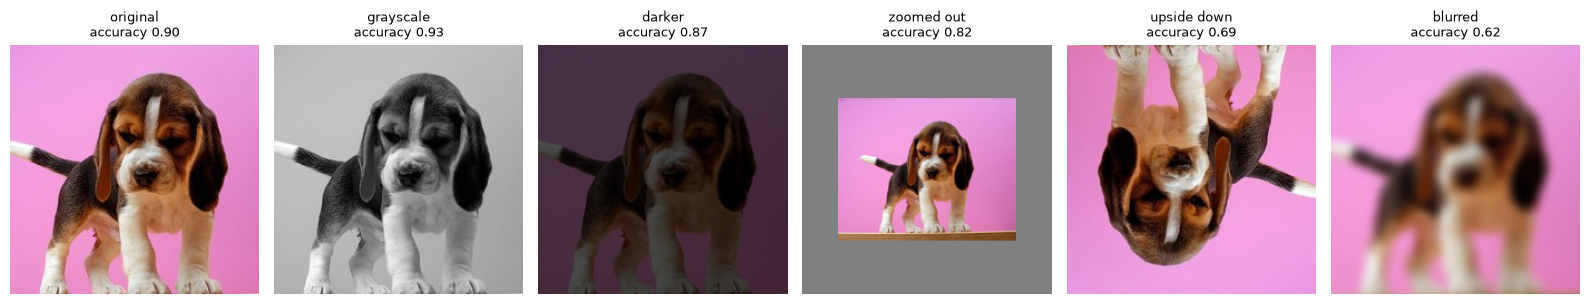

In [4]:
with zipfile.ZipFile(fetch('pets4.zip')) as z:
    z.extractall('.')
BREEDS = sorted(os.listdir('pets4/train'))

weights = models.ResNet18_Weights.DEFAULT
pets_model = models.resnet18(weights=weights)
pets_model.fc = nn.Linear(512, 4)
pets_model.fc.load_state_dict(torch.load(fetch('pets4_head.pt'), map_location='cpu'))
pets_model = pets_model.to(device).eval()

resize = T.Compose([T.Resize(256), T.CenterCrop(224)])
to_input = T.Compose([T.ToTensor(), T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])

def zoom_out(img):
    canvas = Image.new('RGB', img.size, (128, 128, 128))
    canvas.paste(img.resize((img.width // 2, img.height // 2)), (img.width // 4, img.height // 4))
    return canvas

changes = {
    'original': lambda img: img,
    'grayscale': lambda img: img.convert('L').convert('RGB'),
    'darker': lambda img: ImageEnhance.Brightness(img).enhance(0.3),
    'zoomed out': zoom_out,
    'upside down': lambda img: img.rotate(180),
    'blurred': lambda img: img.filter(ImageFilter.GaussianBlur(4)),
}

test_set = datasets.ImageFolder('pets4/test')
labels = torch.tensor(test_set.targets)
photos = [Image.open(path).convert('RGB') for path, _ in test_set.samples]

fig, axes = plt.subplots(1, len(changes), figsize=(16, 3))
shift_results = {}
for ax, (name, change) in zip(axes, changes.items()):
    X = torch.stack([to_input(resize(change(p))) for p in photos]).to(device)
    with torch.no_grad():
        shift_results[name] = (pets_model(X).argmax(dim=1).cpu() == labels).float().mean().item()
    ax.imshow(resize(change(photos[150])))
    ax.set_title(f'{name}\naccuracy {shift_results[name]:.2f}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

Some changes barely matter. Grayscale photos do as well as the originals: the four breeds can be told apart by shape and pattern without color. Darker photos lose a little. Other changes hurt a lot: the model does much worse on blurred photos and on upside-down ones, and loses a fair amount when the animal is small in the frame.

None of these photos is hard for a person. The model fails on them because its training photos (and ImageNet's) were mostly sharp, upright and filled the frame with the subject, and it never had a reason to learn to handle anything else. Two defenses follow from that:

- **Augmentation** (22_0_2) can cover changes you can anticipate, such as random crops, flips, color changes and blur.
- **Test on the conditions the model will actually meet.** A model that will see phone photos taken in dim light should be evaluated on phone photos taken in dim light, not only on a random split of a tidy dataset.

---

## Section 3: Adversarial Examples

The changes above are natural ones. An **adversarial example** is an image changed on purpose, by an amount too small to see, so that the model gets it wrong.

The method uses autograd from 20_0_2 in a new way. Until now we asked for the slope of the loss with respect to each **weight**, to make the loss smaller. We can just as well ask for the slope of the loss with respect to each **pixel** of the input, by setting `requires_grad=True` on the image. Then nudge every pixel a tiny amount in the direction that makes the loss *larger*. Using only the sign of each slope, so every pixel moves by the same small amount up or down, is called the **fast gradient sign method**.

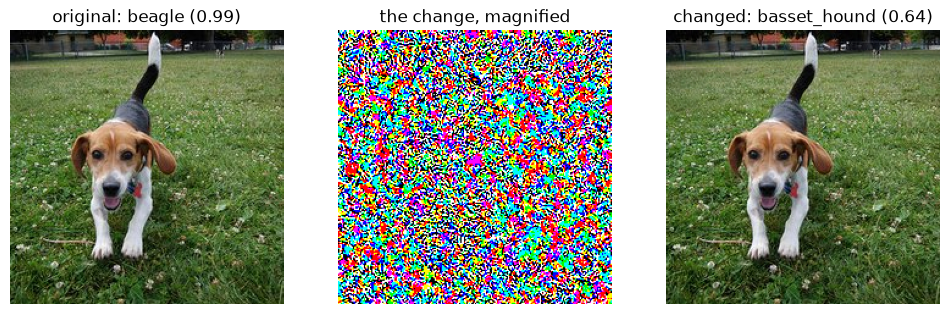

true breed: beagle
largest change to any pixel: 1.2 brightness levels out of 255


In [5]:
def adversarial(X, y, epsilon):
    X = X.clone().requires_grad_(True)
    loss = loss_fn(pets_model(X), y)
    loss.backward()                                       # slopes for every pixel
    return (X + epsilon * X.grad.sign()).detach()         # nudge every pixel uphill

X = torch.stack([to_input(resize(p)) for p in photos]).to(device)
y = labels.to(device)

i = 160
adv = adversarial(X[i:i + 1], y[i:i + 1], epsilon=0.02)
with torch.no_grad():
    p_orig = pets_model(X[i:i + 1]).softmax(dim=1)[0]
    p_adv = pets_model(adv).softmax(dim=1)[0]

std = torch.tensor([0.229, 0.224, 0.225], device=device).view(3, 1, 1)
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(3, 1, 1)
show = lambda t: (t * std + mean).clamp(0, 1).permute(1, 2, 0).cpu()      # undo the normalizing, for display
difference = (adv[0] - X[i]) * std
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(show(X[i])); axes[0].set_title(f'original: {BREEDS[p_orig.argmax()]} ({p_orig.max():.2f})')
axes[1].imshow((difference / difference.abs().max() * 0.5 + 0.5).permute(1, 2, 0).cpu())
axes[1].set_title('the change, magnified')
axes[2].imshow(show(adv[0])); axes[2].set_title(f'changed: {BREEDS[p_adv.argmax()]} ({p_adv.max():.2f})')
for ax in axes:
    ax.axis('off')
plt.show()
print(f'true breed: {BREEDS[labels[i]]}')
print(f'largest change to any pixel: {difference.abs().max().item() * 255:.1f} brightness levels out of 255')

The original and changed photos look identical; the change in the middle had to be magnified enormously to be visible at all. Every pixel moved by about one brightness level out of 255, and the model now gives a different breed. Here is the effect on all 200 test photos for a few sizes of change:

In [6]:
# The direction of the change (the sign of each pixel's slope) is the same whatever its size,
# so compute it once for every photo and reuse it for each size.
directions = []
for j in range(0, len(X), 50):
    batch = X[j:j + 50].clone().requires_grad_(True)
    loss_fn(pets_model(batch), y[j:j + 50]).backward()
    directions.append(batch.grad.sign())
directions = torch.cat(directions)

for epsilon in [0.0, 0.005, 0.01, 0.02]:
    with torch.no_grad():
        acc = (pets_model(X + epsilon * directions).argmax(dim=1) == y).float().mean().item()
    print(f'change of up to {epsilon * 0.229 * 255:4.1f} brightness levels: accuracy {acc:.2f}')

change of up to  0.0 brightness levels: accuracy 0.90


change of up to  0.3 brightness levels: accuracy 0.41


change of up to  0.6 brightness levels: accuracy 0.12


change of up to  1.2 brightness levels: accuracy 0.02


Changes of about one brightness level, which no person could see, are enough to make the model wrong on almost every photo. This works because the model's answer depends on a weighted sum over hundreds of thousands of pixel values, and a tiny nudge to every one of them, each in the most damaging direction, adds up to a large change in the scores. (These smallest changes are below one brightness level, so they only exist inside the computer; saving the photo to a file would round them away. The larger ones would survive, and real attacks use changes a few levels large, which are still very hard to see.)

This attack needed the model's weights, to compute the slopes. Attacks that only see the model's answers also exist, as do physical ones, such as stickers that make a stop sign read as something else to a vision model. Defenses exist too, mainly training on adversarial examples, but none is complete. The main lesson for anyone using these models is that a vision model's confident answer can be changed by things a person would never notice.

---

## Section 4: Bias Against Groups of People

The Pets model's accuracy differed by breed: 38 of 50 Ragdolls right against 50 of 50 beagles (19_1_2). When the classes are groups of people, differences like that are a serious problem, and the overall accuracy hides them in exactly the same way.

The best-known study is **Gender Shades** (Buolamwini and Gebru, 2018). It tested three commercial face-analysis systems that classified photos of faces as male or female, on a set of photos of parliamentarians from six countries, balanced by gender and skin tone. Every system did worst on darker-skinned women and best on lighter-skinned men. The worst error rate for lighter-skinned men was under 1%, while the worst for darker-skinned women was about 35%. Overall accuracy, the number the companies reported, was high for all three systems and gave no sign of this.

The causes connect to things in this course:

- **Who is in the data** (19_0_2, Section 9). The widely used face benchmarks at the time were made up mostly of lighter-skinned faces (about 80% and 86% lighter-skinned in the two the study examined). A model trained and tested mostly on one group can look accurate while being much worse on others, and the test set won't reveal it if the test set has the same imbalance.
- **What gets measured** (19_1_2). Precision and recall per class revealed what accuracy hid for the Pets model. For people, the equivalent is measuring error rates separately for each group, which is what the study did and the companies hadn't.
- **Distribution shift** (Section 2). A face photographed in different lighting, with a different camera, or from a population underrepresented in training is the same kind of problem as a blurred pet photo, except that the people affected didn't choose it.

After the study was published, the companies released updated systems, and a follow-up audit found that the gaps had shrunk considerably (Raji and Buolamwini, 2019). That's the practical lesson: disaggregated evaluation, meaning accuracy reported for each group separately, finds problems that a single number hides, and once found they can often be reduced.

---

## Summary

- **Shortcut learning**: given a planted marker that predicted the class, a CNN learned the marker. It was nearly perfect on marked images, poor on clean ones, and followed the marker when it was wrong. Real models have learned hospital markings and rulers. Test on data collected differently from the training data.
- **Distribution shift**: the Pets model did as well on grayscale photos but much worse on blurred, upside-down or zoomed-out ones, because its training photos rarely looked like that. Augmentation helps with changes you can anticipate; testing on realistic conditions finds the rest.
- **Adversarial examples**: using autograd on the input pixels, changes of about one brightness level, invisible to a person, made the Pets model wrong on almost every test photo.
- **Bias**: Gender Shades found commercial face-analysis error rates from under 1% to about 35% depending on gender and skin tone, hidden by high overall accuracy. Imbalanced data causes it; measuring accuracy for each group separately reveals it.
- In every case the overall test accuracy looked fine. What you test on, and how you break the results down, decides whether you find the problem.

**Next:** 22_2 turns from classifying images to making them: an autoencoder that removes noise from Fashion-MNIST images, and a pretrained diffusion model that generates images by removing noise again and again.